# Climate Champions: Scratch Assessment Analysis

This notebook examines Scratch pre-test and post-test assessment results.

The analysis includes:
- Verification of scores against the supplied answer keys.
- Overall assessment averages and participant score changes.
- Score distributions.
- Question-level correct-answer rates.
- Paired answer transitions.

According to the source workbook, the Scratch pre-test and post-test use
identical questions. This supports paired item comparisons.

Observed changes describe this participant group. Without a comparison
group, they do not establish that the program alone caused the changes.

In [1]:
from pathlib import Path
from textwrap import fill

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

current = Path.cwd().resolve()

ROOT = next(
    (
        folder
        for folder in [current, *current.parents]
        if (folder / "data" / "processed").is_dir()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError("Cannot find data/processed.")

DATA = ROOT / "data" / "processed"
FIGURES = ROOT / "outputs" / "figures" / "scratch"
TABLES = ROOT / "outputs" / "tables" / "scratch"

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

PRE_COLOR = "#7952B3"
POST_COLOR = "#E88932"

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

def save_figure(fig, filename):
    fig.savefig(
        FIGURES / filename,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

print("Project:", ROOT)

Project: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA


In [2]:
scratch = pd.read_csv(
    DATA / "scratch.csv",
    dtype={"participant_id": "string"}
)

questions = pd.read_csv(DATA / "question_reference.csv")

scratch_keys = questions.loc[
    questions["track"].eq("scratch")
].copy()

print("Scratch records:", len(scratch))
print("Answer-key entries:", len(scratch_keys))

display(
    scratch_keys[
        ["phase", "question", "answer_key_raw", "skill"]
    ].reset_index(drop=True)
)

Scratch records: 22
Answer-key entries: 10


,phase,question,answer_key_raw,skill
0,pre,q1,C,Decomposition
1,pre,q2,A,Pattern Recognition
2,pre,q3,D,Abstraction
3,pre,q4,B,Algorithm Design
4,pre,q5,C,Looping / repetition
5,post,q1,C,Decomposition
6,post,q2,A,Pattern Recognition
7,post,q3,D,Abstraction
8,post,q4,B,Algorithm Design
9,post,q5,C,Looping / repetition


## 1. Verify Scores and Item Comparability

Each answer is checked against its phase-specific answer key.
Correct answers receive one point, giving a maximum score of five.

Recalculated totals, percentages, and score changes are compared with the
workbook values.

The reference metadata is also checked for matching pre/post skill labels
and answer keys. These checks support the workbook's statement that the
questions are identical, but do not independently verify the original
question wording.

In [3]:
if scratch.empty:
    raise ValueError("The Scratch dataset is empty.")

if scratch["participant_id"].isna().any():
    raise ValueError("Missing participant IDs.")

if scratch["participant_id"].duplicated().any():
    raise ValueError("Duplicate participant IDs.")

if not scratch["track"].eq("scratch").all():
    raise ValueError("Unexpected track in scratch.csv.")

expected_keys = {
    (phase, f"q{q}")
    for phase in ["pre", "post"]
    for q in range(1, 6)
}

actual_keys = set(
    scratch_keys[["phase", "question"]]
    .itertuples(index=False, name=None)
)

if (
    actual_keys != expected_keys
    or scratch_keys.duplicated(["phase", "question"]).any()
):
    raise ValueError("Missing or duplicate answer-key entries.")

identical_flags = (
    scratch_keys["identical_pre_post_items"]
    .astype("string")
    .str.lower()
)

if not identical_flags.eq("true").all():
    raise ValueError("Reference does not confirm identical pre/post items.")

pre_keys = (
    scratch_keys.loc[scratch_keys["phase"].eq("pre")]
    .set_index("question")
    .sort_index()
)

post_keys = (
    scratch_keys.loc[scratch_keys["phase"].eq("post")]
    .set_index("question")
    .sort_index()
)

for column in ["answer_key_raw", "skill"]:
    pre_values = pre_keys[column].astype("string").str.strip()
    post_values = post_keys[column].astype("string").str.strip()

    if not pre_values.eq(post_values).all():
        raise ValueError(f"Pre/post reference mismatch: {column}")

item_rows = []

for phase in ["pre", "post"]:
    correct_columns = []

    for q in range(1, 6):
        question = f"q{q}"
        answer_column = f"{phase}_{question}"

        key_row = scratch_keys.loc[
            scratch_keys["phase"].eq(phase)
            & scratch_keys["question"].eq(question)
        ].iloc[0]

        correct_answer = str(key_row["answer_key_raw"]).strip().upper()

        answers = (
            scratch[answer_column]
            .astype("string")
            .str.strip()
            .str.upper()
        )

        if correct_answer not in {"A", "B", "C", "D"}:
            raise ValueError(f"Unresolved key: {phase} {question}")

        if not answers.isin(["A", "B", "C", "D"]).all():
            raise ValueError(f"Unresolved answers: {answer_column}")

        correct_column = f"{phase}_{question}_correct"

        scratch[correct_column] = answers.eq(correct_answer).astype(int)
        correct_columns.append(correct_column)

        item_rows.append({
            "phase": phase,
            "question": question,
            "skill": key_row["skill"],
            "n_answered": len(answers),
            "n_correct": int(scratch[correct_column].sum()),
            "correct_rate_pct": scratch[correct_column].mean() * 100
        })

    scratch[f"{phase}_correct"] = scratch[correct_columns].sum(axis=1)
    scratch[f"{phase}_score_pct"] = scratch[f"{phase}_correct"] * 20

scratch["change_points"] = (
    scratch["post_correct"] - scratch["pre_correct"]
)

scratch["change_pp"] = (
    scratch["post_score_pct"] - scratch["pre_score_pct"]
)

items = pd.DataFrame(item_rows)

comparisons = [
    ("pre_correct", "pre_correct_workbook"),
    ("post_correct", "post_correct_workbook"),
    ("pre_score_pct", "pre_score_pct_workbook"),
    ("post_score_pct", "post_score_pct_workbook"),
    ("change_pp", "change_pp_workbook"),
]

verification = pd.DataFrame([
    {
        "check": calculated,
        "matching_records": int(
            np.isclose(scratch[calculated], scratch[original]).sum()
        ),
        "mismatching_records": int(
            (~np.isclose(scratch[calculated], scratch[original])).sum()
        )
    }
    for calculated, original in comparisons
])

display(verification)

if verification["mismatching_records"].sum() > 0:
    raise ValueError("Review score discrepancies before continuing.")

print("PASS: scores match the workbook.")
print("PASS: pre/post reference labels and answer keys match.")

,check,matching_records,mismatching_records
0,pre_correct,22,0
1,post_correct,22,0
2,pre_score_pct,22,0
3,post_score_pct,22,0
4,change_pp,22,0


PASS: scores match the workbook.
PASS: pre/post reference labels and answer keys match.


## 2. Overall Assessment Results

Mean and median scores summarize group performance.
Standard deviations describe variation between participants.

Scores are reported both as correct answers out of five and percentages.
A difference of one correct answer equals 20 percentage points.

,phase,participants,mean_correct,median_correct,sd_correct,minimum_correct,maximum_correct,mean_score_pct
0,pre,22,2.50,3.0,1.01,1,4,50.00
1,post,22,3.77,4.0,1.07,1,5,75.45


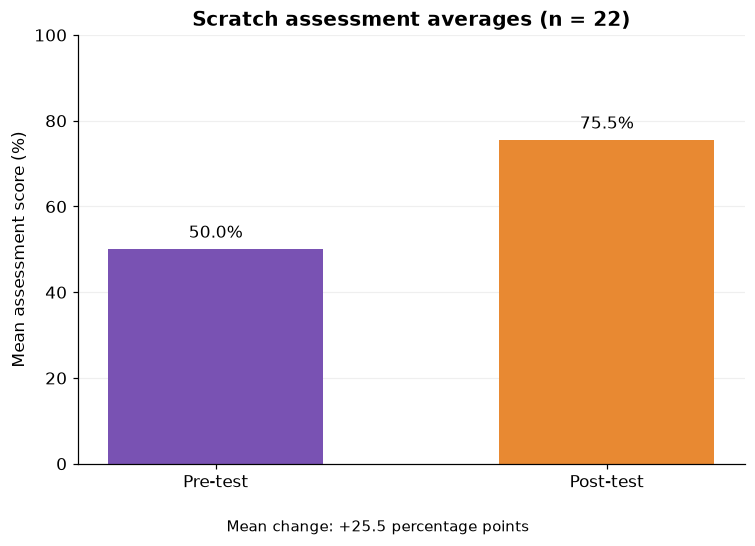

In [4]:
n = len(scratch)

summary = pd.DataFrame([
    {
        "phase": phase,
        "participants": n,
        "mean_correct": scratch[f"{phase}_correct"].mean(),
        "median_correct": scratch[f"{phase}_correct"].median(),
        "sd_correct": scratch[f"{phase}_correct"].std(),
        "minimum_correct": scratch[f"{phase}_correct"].min(),
        "maximum_correct": scratch[f"{phase}_correct"].max(),
        "mean_score_pct": scratch[f"{phase}_score_pct"].mean(),
    }
    for phase in ["pre", "post"]
])

pre_mean = scratch["pre_score_pct"].mean()
post_mean = scratch["post_score_pct"].mean()
mean_change_pp = scratch["change_pp"].mean()

display(summary.round(2))

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    ["Pre-test", "Post-test"],
    [pre_mean, post_mean],
    color=[PRE_COLOR, POST_COLOR],
    width=0.55
)

ax.bar_label(
    bars,
    labels=[f"{pre_mean:.1f}%", f"{post_mean:.1f}%"],
    padding=5
)

ax.set_ylim(0, 100)
ax.set_ylabel("Mean assessment score (%)")
ax.set_title(f"Scratch assessment averages (n = {n})")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.text(
    0.5, 0.02,
    f"Mean change: {mean_change_pp:+.1f} percentage points",
    ha="center", fontsize=10
)

fig.tight_layout(rect=[0, 0.06, 1, 1])
save_figure(fig, "01_scratch_pre_post_averages.png")
plt.show()

## 3. Participant Score Changes

Participants are classified by whether their post-test total was higher,
unchanged, or lower than their pre-test total.

This shows whether the group-level average change was shared broadly
across participants.

,outcome,participants,percent
0,Higher post-test score,21,95.45
1,Unchanged score,0,0.00
2,Lower post-test score,1,4.55


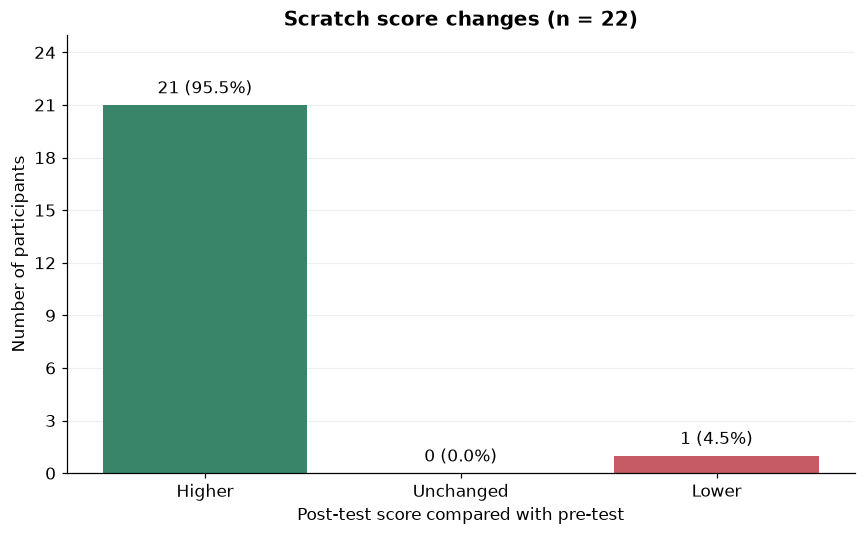

In [5]:
scratch["score_change_group"] = np.select(
    [
        scratch["change_points"].gt(0),
        scratch["change_points"].lt(0)
    ],
    ["Higher post-test score", "Lower post-test score"],
    default="Unchanged score"
)

group_order = [
    "Higher post-test score",
    "Unchanged score",
    "Lower post-test score"
]

change_summary = (
    scratch["score_change_group"]
    .value_counts()
    .reindex(group_order, fill_value=0)
    .rename_axis("outcome")
    .reset_index(name="participants")
)

change_summary["percent"] = (
    change_summary["participants"] / n * 100
)

display(change_summary.round(2))

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Higher", "Unchanged", "Lower"],
    change_summary["participants"],
    color=["#38856A", "#9299A3", "#C65B65"]
)

ax.bar_label(
    bars,
    labels=[
        f"{count} ({percent:.1f}%)"
        for count, percent in zip(
            change_summary["participants"],
            change_summary["percent"]
        )
    ],
    padding=5
)

ax.set_ylim(0, n + 3)
ax.set_ylabel("Number of participants")
ax.set_xlabel("Post-test score compared with pre-test")
ax.set_title(f"Scratch score changes (n = {n})")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
save_figure(fig, "02_scratch_score_changes.png")
plt.show()

## 4. Score Distributions

Score frequencies show how many participants scored zero through five
in each assessment.

The distribution helps identify concentrations of low scores, variation
between participants, and possible ceiling effects when participants
already score near the maximum.

,score,pre_count,post_count
0,0,0,0
1,1,5,1
2,2,4,2
3,3,10,3
4,4,3,11
5,5,0,5


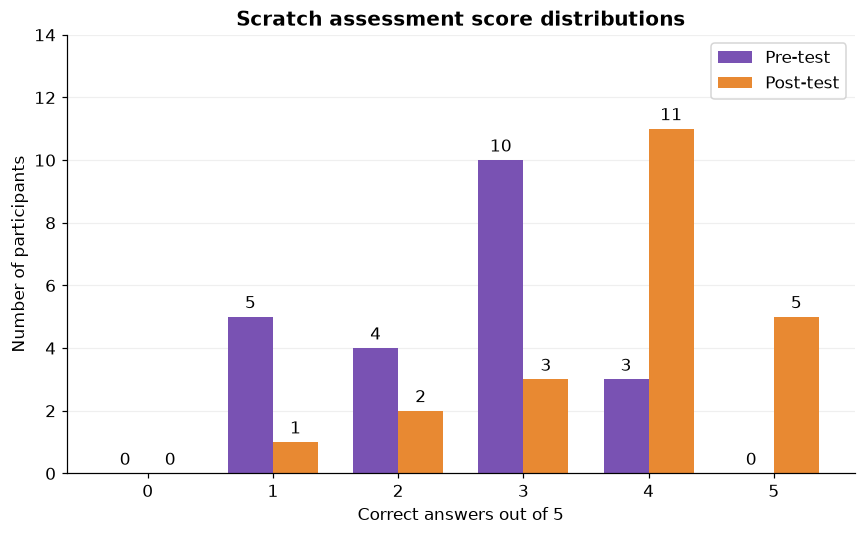

In [6]:
distribution = pd.DataFrame({
    "score": range(6),
    "pre_count": (
        scratch["pre_correct"].value_counts()
        .reindex(range(6), fill_value=0).to_numpy()
    ),
    "post_count": (
        scratch["post_correct"].value_counts()
        .reindex(range(6), fill_value=0).to_numpy()
    )
})

display(distribution)

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(6)
width = 0.36

pre_bars = ax.bar(
    x - width / 2, distribution["pre_count"],
    width, label="Pre-test", color=PRE_COLOR
)

post_bars = ax.bar(
    x + width / 2, distribution["post_count"],
    width, label="Post-test", color=POST_COLOR
)

ax.bar_label(pre_bars, padding=3)
ax.bar_label(post_bars, padding=3)

ax.set_xticks(x)
ax.set_xlabel("Correct answers out of 5")
ax.set_ylabel("Number of participants")
ax.set_title("Scratch assessment score distributions")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_ylim(
    0,
    max(distribution["pre_count"].max(),
        distribution["post_count"].max()) + 3
)

ax.legend()
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
save_figure(fig, "03_scratch_score_distributions.png")
plt.show()

### Interpretation of Score Distributions

The score distribution shifted toward higher totals after the session.

Before the session, 3 of 22 participants (13.6%) scored four out of five,
and none scored five. After the session, 16 participants (72.7%) scored
four or five, including five who answered every question correctly.

The number scoring one or two decreased from nine (40.9%) to three
(13.6%). The median increased from three to four correct answers.

The paired participant results also show that 21 of 22 participants
had higher post-test totals. The increase in the group average was
therefore accompanied by higher scores for most participants.

## 5. Question-Level Performance

Pre/post correct-answer rates are compared for each matched question.
Change is expressed in percentage points.

Each question represents a limited sample of a broader skill. High accuracy
on one item should not be described as complete mastery of that skill.

,question,skill,pre_n_correct,pre_correct_rate_pct,post_n_correct,post_correct_rate_pct,change_pp
0,q1,Decomposition,21,95.45,19,86.36,-9.09
1,q2,Pattern Recognition,14,63.64,17,77.27,13.64
2,q3,Abstraction,0,0.00,10,45.45,45.45
3,q4,Algorithm Design,16,72.73,20,90.91,18.18
4,q5,Looping / repetition,4,18.18,17,77.27,59.09


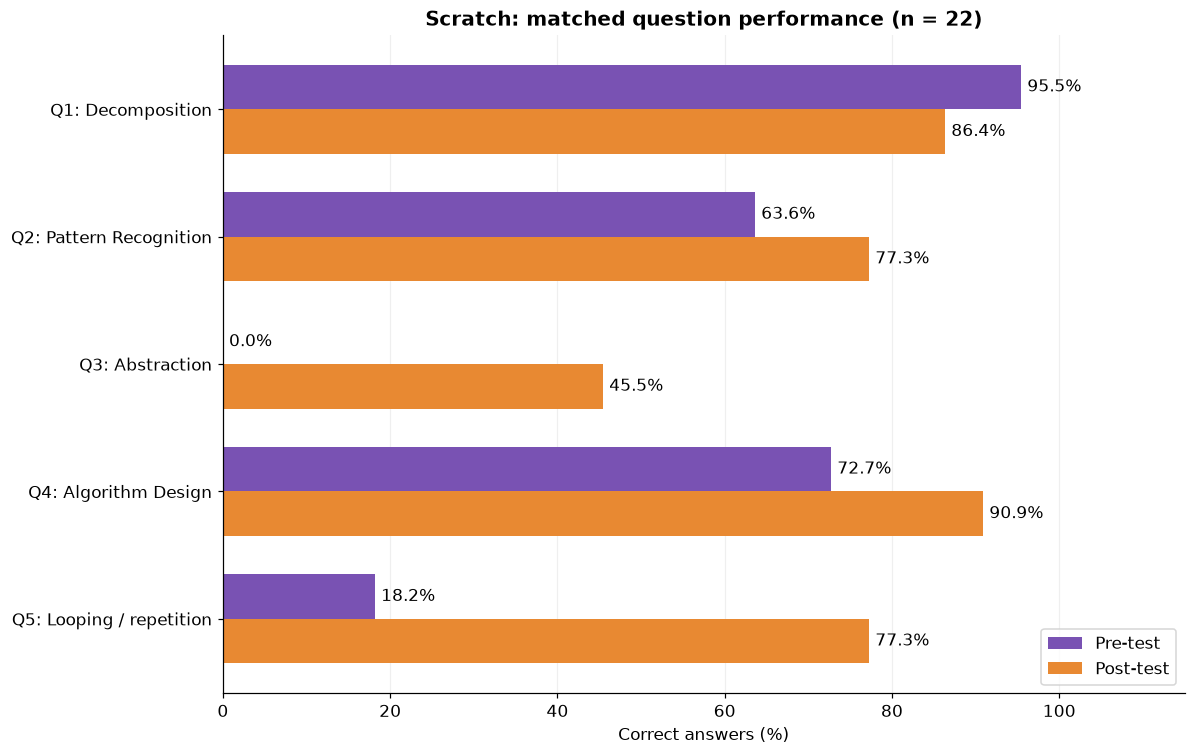

In [7]:
pre_items = (
    items.loc[items["phase"].eq("pre"),
              ["question", "skill", "n_correct", "correct_rate_pct"]]
    .rename(columns={
        "n_correct": "pre_n_correct",
        "correct_rate_pct": "pre_correct_rate_pct"
    })
)

post_items = (
    items.loc[items["phase"].eq("post"),
              ["question", "n_correct", "correct_rate_pct"]]
    .rename(columns={
        "n_correct": "post_n_correct",
        "correct_rate_pct": "post_correct_rate_pct"
    })
)

item_comparison = (
    pre_items.merge(post_items, on="question", validate="one_to_one")
    .sort_values("question")
    .reset_index(drop=True)
)

item_comparison["change_pp"] = (
    item_comparison["post_correct_rate_pct"]
    - item_comparison["pre_correct_rate_pct"]
)

display(item_comparison.round(2))

labels = [
    fill(f"{row.question.upper()}: {row.skill}", width=40)
    for row in item_comparison.itertuples()
]

y = np.arange(len(item_comparison))
height = 0.35

fig, ax = plt.subplots(figsize=(11, 7))

pre_bars = ax.barh(
    y - height / 2,
    item_comparison["pre_correct_rate_pct"],
    height, label="Pre-test", color=PRE_COLOR
)

post_bars = ax.barh(
    y + height / 2,
    item_comparison["post_correct_rate_pct"],
    height, label="Post-test", color=POST_COLOR
)

ax.bar_label(pre_bars, fmt="%.1f%%", padding=4)
ax.bar_label(post_bars, fmt="%.1f%%", padding=4)

ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlim(0, 115)
ax.set_xticks(np.arange(0, 101, 20))
ax.set_xlabel("Correct answers (%)")
ax.set_title(f"Scratch: matched question performance (n = {n})")
ax.legend(loc="lower right")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)

fig.tight_layout()
save_figure(fig, "04_scratch_item_performance.png")
plt.show()

## 6. Paired Answer Transitions

For each question, participants fall into four categories:

- Wrong to right: incorrect pre-test answer, correct post-test answer.
- Right to wrong: correct pre-test answer, incorrect post-test answer.
- Right both times: correct in both phases.
- Wrong both times: incorrect in both phases.

Wrong-to-right counts show positive answer changes. Right-to-wrong counts
show negative answer changes. Their difference equals the net increase
in correct answers for that item.

These transitions describe responses and do not directly establish why
an answer changed.

,question,skill,wrong_to_right,right_to_wrong,right_both,wrong_both,net_correct_change
0,q1,Decomposition,1,3,18,0,-2
1,q2,Pattern Recognition,4,1,13,4,3
2,q3,Abstraction,10,0,0,12,10
3,q4,Algorithm Design,4,0,16,2,4
4,q5,Looping / repetition,14,1,3,4,13


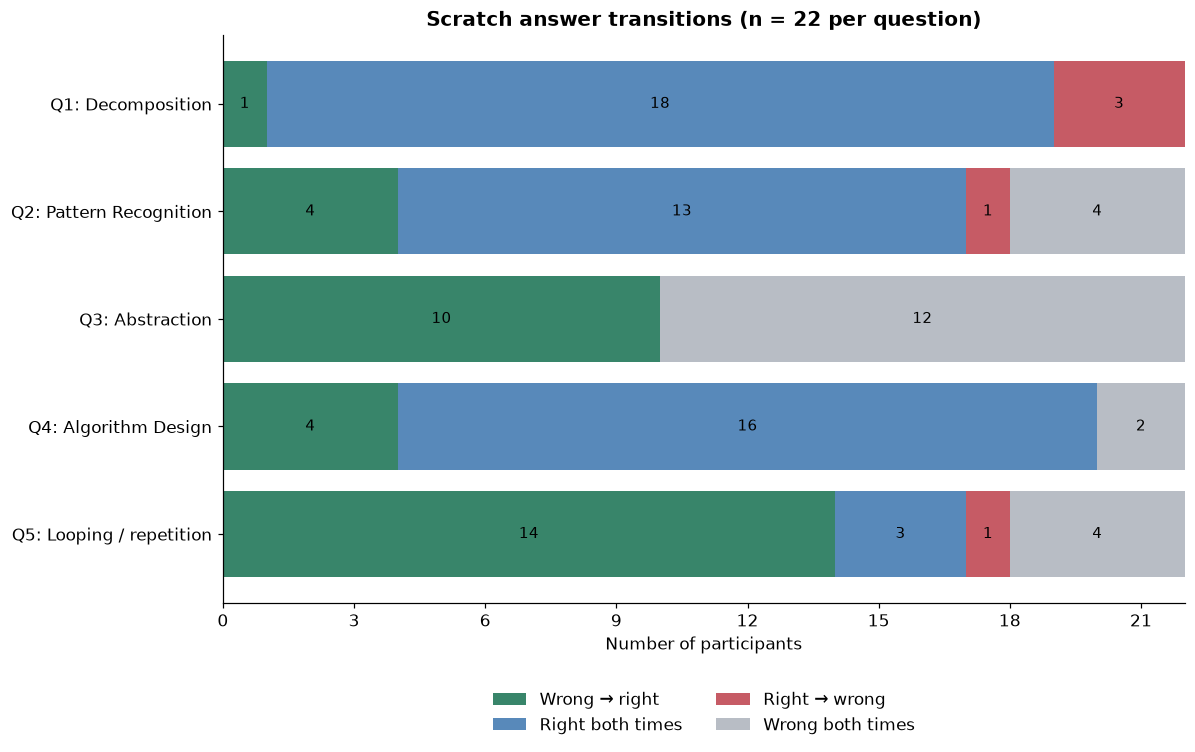

In [8]:
transition_rows = []

for q in range(1, 6):
    question = f"q{q}"

    pre = scratch[f"pre_{question}_correct"]
    post = scratch[f"post_{question}_correct"]

    transition_rows.append({
        "question": question,
        "skill": pre_keys.loc[question, "skill"],
        "wrong_to_right": int(((pre == 0) & (post == 1)).sum()),
        "right_to_wrong": int(((pre == 1) & (post == 0)).sum()),
        "right_both": int(((pre == 1) & (post == 1)).sum()),
        "wrong_both": int(((pre == 0) & (post == 0)).sum()),
    })

transitions = pd.DataFrame(transition_rows)

transition_columns = [
    "wrong_to_right", "right_to_wrong", "right_both", "wrong_both"
]

assert transitions[transition_columns].sum(axis=1).eq(n).all()

transitions["net_correct_change"] = (
    transitions["wrong_to_right"] - transitions["right_to_wrong"]
)

assert np.array_equal(
    transitions["net_correct_change"].to_numpy(),
    (
        item_comparison["post_n_correct"]
        - item_comparison["pre_n_correct"]
    ).to_numpy()
)

display(transitions)

fig, ax = plt.subplots(figsize=(11, 7))

left = np.zeros(len(transitions))

transition_styles = [
    ("wrong_to_right", "Wrong → right", "#38856A"),
    ("right_both", "Right both times", "#5889BA"),
    ("right_to_wrong", "Right → wrong", "#C65B65"),
    ("wrong_both", "Wrong both times", "#B8BDC5"),
]

for column, label, color in transition_styles:
    values = transitions[column].to_numpy()

    bars = ax.barh(
        np.arange(len(transitions)),
        values,
        left=left,
        label=label,
        color=color
    )

    ax.bar_label(
        bars,
        labels=[str(v) if v > 0 else "" for v in values],
        label_type="center",
        fontsize=10
    )

    left += values

ax.set_yticks(np.arange(len(transitions)))
ax.set_yticklabels([
    fill(f"{row.question.upper()}: {row.skill}", width=40)
    for row in transitions.itertuples()
])

ax.invert_yaxis()
ax.set_xlim(0, n)
ax.set_xlabel("Number of participants")
ax.set_title(f"Scratch answer transitions (n = {n} per question)")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=2,
    frameon=False
)

fig.tight_layout()
save_figure(fig, "05_scratch_answer_transitions.png")
plt.show()

### Interpretation of Question-Level Changes

**Looping/repetition showed the largest increase.** Correct answers rose
from 4 of 22 (18.2%) to 17 of 22 (77.3%). Fourteen participants changed
from wrong to right, while one changed from right to wrong.

**Abstraction improved but remained the main assessment gap.**
No participant answered this item correctly in the pre-test. Ten
answered it correctly in the post-test (45.5%), while twelve answered
incorrectly in both phases. Additional guided practice and review of
the item's wording and answer options are warranted.

**Algorithm design had the highest post-test accuracy.**
Correct answers increased from 16 to 20 (90.9%). All sixteen initially
correct participants remained correct, and four changed from wrong
to right.

**Pattern recognition increased from 63.6% to 77.3%.**
Four participants changed from wrong to right, one changed from right
to wrong, and four answered incorrectly in both phases.

**Decomposition was the only item with a lower post-test rate.**
Correct answers decreased from 21 to 19 (95.5% to 86.4%). Three
participants changed from right to wrong and one changed from wrong
to right. The high pre-test accuracy left little room for an increase,
but it does not explain the incorrect post-test answers. Their cause
cannot be determined from these responses alone.

Across all five questions, there were 33 wrong-to-right transitions
and five right-to-wrong transitions: a net increase of 28 correct
answers across the group. These are participant-question observations,
not counts of distinct participants.

These findings describe performance on five assessment items.
They do not establish broad skill mastery or isolate the program's
causal effect.

In [9]:
highest_post = item_comparison.loc[
    item_comparison["post_correct_rate_pct"].eq(
        item_comparison["post_correct_rate_pct"].max()
    )
]

lowest_post = item_comparison.loc[
    item_comparison["post_correct_rate_pct"].eq(
        item_comparison["post_correct_rate_pct"].min()
    )
]

largest_change = item_comparison.loc[
    item_comparison["change_pp"].eq(
        item_comparison["change_pp"].max()
    )
]

def describe_post(df):
    return "; ".join(
        f"{row.skill}: {row.post_correct_rate_pct:.1f}% "
        f"({row.post_n_correct}/{n})"
        for row in df.itertuples()
    )

def describe_change(df):
    return "; ".join(
        f"{row.skill}: {row.change_pp:+.1f} percentage points"
        for row in df.itertuples()
    )

counts = change_summary.set_index("outcome")["participants"]

total_positive = transitions["wrong_to_right"].sum()
total_negative = transitions["right_to_wrong"].sum()

findings_md = f"""
## Scratch Findings

The analysis included **{n} participant records**.
Recalculated scores matched the supplied workbook values.

The mean score changed from **{pre_mean:.1f}%**
({scratch['pre_correct'].mean():.2f}/5) to **{post_mean:.1f}%**
({scratch['post_correct'].mean():.2f}/5), a difference of
**{mean_change_pp:+.1f} percentage points**.

The median score changed from **{scratch['pre_correct'].median():.1f}/5**
to **{scratch['post_correct'].median():.1f}/5**.

### Participant Outcomes

- Higher post-test totals: **{counts['Higher post-test score']}**
  ({counts['Higher post-test score'] / n * 100:.1f}%).
- Unchanged totals: **{counts['Unchanged score']}**
  ({counts['Unchanged score'] / n * 100:.1f}%).
- Lower post-test totals: **{counts['Lower post-test score']}**
  ({counts['Lower post-test score'] / n * 100:.1f}%).

### Question-Level Results

Highest post-test accuracy:
**{describe_post(highest_post)}**.

Lowest post-test accuracy:
**{describe_post(lowest_post)}**.

Largest numerical item change:
**{describe_change(largest_change)}**.

Across the {n * 5} paired participant-question observations,
**{total_positive}** changed from wrong to right and
**{total_negative}** changed from right to wrong.
These are answer-transition counts, not unique participant counts.

### Interpretation

The paired results describe changes on the same assessment items,
according to the source workbook. Possible influences include learning,
familiarity with repeated questions, and guessing.

There is no comparison group, so the observed change cannot be attributed
exclusively to the program. The five-item assessment also provides limited
coverage of broader computational-thinking skills.
"""

display(Markdown(findings_md))


## Scratch Findings

The analysis included **22 participant records**.
Recalculated scores matched the supplied workbook values.

The mean score changed from **50.0%**
(2.50/5) to **75.5%**
(3.77/5), a difference of
**+25.5 percentage points**.

The median score changed from **3.0/5**
to **4.0/5**.

### Participant Outcomes

- Higher post-test totals: **21**
  (95.5%).
- Unchanged totals: **0**
  (0.0%).
- Lower post-test totals: **1**
  (4.5%).

### Question-Level Results

Highest post-test accuracy:
**Algorithm Design: 90.9% (20/22)**.

Lowest post-test accuracy:
**Abstraction: 45.5% (10/22)**.

Largest numerical item change:
**Looping / repetition: +59.1 percentage points**.

Across the 110 paired participant-question observations,
**33** changed from wrong to right and
**5** changed from right to wrong.
These are answer-transition counts, not unique participant counts.

### Interpretation

The paired results describe changes on the same assessment items,
according to the source workbook. Possible influences include learning,
familiarity with repeated questions, and guessing.

There is no comparison group, so the observed change cannot be attributed
exclusively to the program. The five-item assessment also provides limited
coverage of broader computational-thinking skills.


In [10]:
priority_skills = "; ".join(lowest_post["skill"].astype(str))

declining_items = item_comparison.loc[
    item_comparison["change_pp"].lt(0)
]

if declining_items.empty:
    decline_note = (
        "No item had a lower group-level post-test correct-answer rate. "
        "Individual right-to-wrong transitions should still be reviewed."
    )
else:
    decline_note = (
        "Review the following items with lower post-test accuracy: "
        + describe_change(declining_items)
        + ". Check item wording, answer choices, and instructional coverage "
          "before proposing an explanation."
    )

recommendations_md = f"""
## Recommendations and Next Steps

### Target the Lowest Post-Test Accuracy

Prioritize additional practice for **{priority_skills}**.
Use a worked example, a guided task, and several new assessment questions
to check whether participants can apply the concept.

### Review Answer Transitions

{decline_note}

Use wrong-to-right and right-to-wrong counts alongside overall item rates.
A positive net change can conceal difficulties experienced by some
participants.

### Extend Assessment Coverage

Use more than one question per skill and include a short practical Scratch
task. This provides broader evidence than a single multiple-choice item.

A delayed follow-up assessment would help examine whether understanding
is retained beyond the immediate post-test.

### Prediction Analysis

A later notebook will explore whether pre-test information predicts
post-test scores. Predictions will be evaluated on held-out participants
and compared with simple baselines.

Prediction performance will be reported separately from observed
pre/post score changes.
"""

display(Markdown(recommendations_md))


## Recommendations and Next Steps

### Target the Lowest Post-Test Accuracy

Prioritize additional practice for **Abstraction**.
Use a worked example, a guided task, and several new assessment questions
to check whether participants can apply the concept.

### Review Answer Transitions

Review the following items with lower post-test accuracy: Decomposition: -9.1 percentage points. Check item wording, answer choices, and instructional coverage before proposing an explanation.

Use wrong-to-right and right-to-wrong counts alongside overall item rates.
A positive net change can conceal difficulties experienced by some
participants.

### Extend Assessment Coverage

Use more than one question per skill and include a short practical Scratch
task. This provides broader evidence than a single multiple-choice item.

A delayed follow-up assessment would help examine whether understanding
is retained beyond the immediate post-test.

### Prediction Analysis

A later notebook will explore whether pre-test information predicts
post-test scores. Predictions will be evaluated on held-out participants
and compared with simple baselines.

Prediction performance will be reported separately from observed
pre/post score changes.


In [11]:
tables_to_save = {
    "scratch_score_verification.csv": verification,
    "scratch_score_summary.csv": summary,
    "scratch_change_summary.csv": change_summary,
    "scratch_score_distribution.csv": distribution,
    "scratch_item_performance.csv": items,
    "scratch_item_comparison.csv": item_comparison,
    "scratch_answer_transitions.csv": transitions,
}

for filename, table in tables_to_save.items():
    table.to_csv(TABLES / filename, index=False)

full_findings = findings_md.strip() + "\n\n" + recommendations_md.strip()

(TABLES / "scratch_findings.md").write_text(
    full_findings,
    encoding="utf-8"
)

print("Saved 5 figures to:", FIGURES)
print("Saved 7 tables and findings to:", TABLES)

Saved 5 figures to: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\outputs\figures\scratch
Saved 7 tables and findings to: C:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\outputs\tables\scratch
